In [1]:
import neuron
from neuron import h
import matplotlib.pyplot as plt
import numpy as np
import sys

from hnn_tuning import NETWORK_SIM, HNN_CORE_MOD
neuron.load_mechanisms(str(HNN_CORE_MOD))
h.load_file("stdrun.hoc")
pathfig = str(NETWORK_SIM / 'figures' / 'conn')

from hnn_tuning.l5_plot_utils import get_l5pyr

plt.rcParams['pdf.fonttype'] = 'truetype'
plt.rcParams['pdf.fonttype'] = 42

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_bro

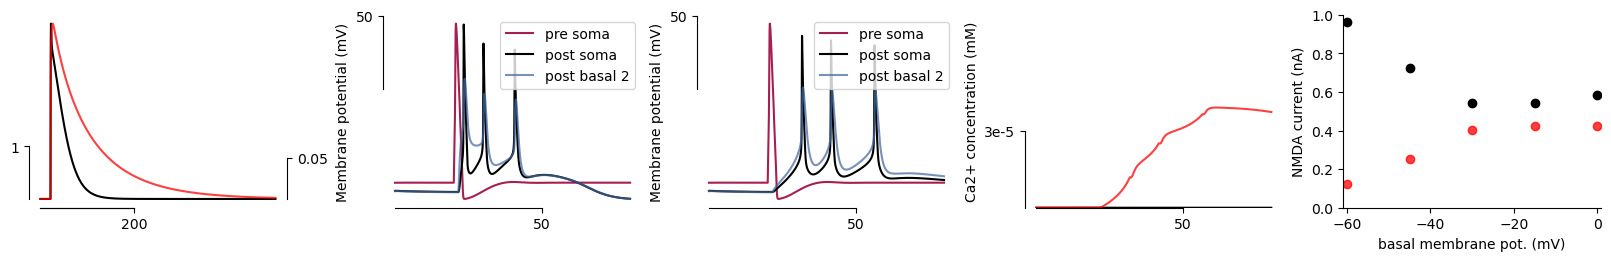

In [2]:
fig, ax = plt.subplots(1, 5, figsize=(16,2.5), constrained_layout=True)

# NMDA current comparison without spiking

# pre-synapse 
soma_pre = h.Section(name='soma')
soma_pre.L = soma_pre.diam = 12
soma_pre.Ra = 100
soma_pre.cm = 1
soma_pre.insert('hh') 

# clamp
stim = h.IClamp(soma_pre(0.5))
stim.delay = 20
stim.dur = 2    
stim.amp = 0.5

# post-synapse
basal_post = h.Section(name='basal')
basal_post.L = 255
basal_post.diam = 8.5
basal_post.Ra = 100
basal_post.cm = 1
basal_post.insert('pas')

syn = h.Exp2Syn(basal_post(0.5))
syn.tau1 = 1
syn.tau2 = 20
syn.e = 0.0

nc = h.NetCon(soma_pre(0.5)._ref_v, syn, sec=soma_pre)
nc.weight[0] = 0.1
nc.delay = 1

t = h.Vector().record(h._ref_t)
exp2curr = h.Vector().record(syn._ref_i)

h.finitialize(-65)
h.continuerun(500)

h('forall delete_section()')  # clean up sections

del stim, syn, nc, soma_pre, basal_post


## NMDA GAO

# pre-synapse 
soma_pre = h.Section(name='soma')
soma_pre.L = soma_pre.diam = 12
soma_pre.Ra = 100
soma_pre.cm = 1
soma_pre.insert('hh') 

# clamp
stim = h.IClamp(soma_pre(0.5))
stim.delay = 20
stim.dur = 2    
stim.amp = 0.5

# post-synapse
basal_post = h.Section(name='basal')
basal_post.L = 255
basal_post.diam = 8.5
basal_post.Ra = 100
basal_post.cm = 1
basal_post.insert('pas')

syn = h.NMDA_gao(basal_post(0.5))

nc = h.NetCon(soma_pre(0.5)._ref_v, syn, sec=soma_pre)
nc.weight[0] = 0.1
nc.delay = 1

t = h.Vector().record(h._ref_t)
gaocurr = h.Vector().record(syn._ref_i)

h.finitialize(-65)
h.continuerun(500)


ax[0].plot(t.as_numpy(), np.abs(exp2curr.as_numpy()), color='k', alpha=1)
ax2 = ax[0].twinx()
ax2.plot(t.as_numpy(), np.abs(gaocurr.as_numpy()), color='r', alpha=0.75)

l5pyr = get_l5pyr(add_syn='Exp2Syn', syn_loc='basal_2')
l5pyr.syn.e 
l5pyr.syn.tau1 = 0.5
l5pyr.syn.tau2 = 5.0
soma = h.Section(name='soma')
soma.L = soma.diam = 12
soma.Ra = 100
soma.cm = 1
soma.insert('hh')

nc = h.NetCon(soma(0.5)._ref_v, l5pyr.syn, sec=soma)
nc.weight[0] = 0.2
nc.delay = 1

stim = h.IClamp(soma(0.5))
stim.delay = 20
stim.dur = 2    
stim.amp = 0.5

t = h.Vector().record(h._ref_t)
v_pre = h.Vector().record(soma(0.5)._ref_v)
v_post_basal = h.Vector().record(l5pyr._nrn_sections['basal_2'](0.5)._ref_v)
v_post_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
nmda_curr = h.Vector().record(l5pyr.syn._ref_i)
ca_curr = h.Vector().record(l5pyr._nrn_sections['basal_2'](0.5)._ref_ica)
ca_con = h.Vector().record(l5pyr._nrn_sections['basal_2'](0.5)._ref_cai)

h.finitialize()
h.continuerun(80)

ax[1].plot(t, v_pre, color='#a52051', label='pre soma')
ax[1].plot(t, v_post_soma, color='k', label='post soma')
ax[1].plot(t, v_post_basal, color='#436aa1', label='post basal 2', alpha=0.73)
ax[1].set_ylabel('Membrane potential (mV)')
ax[1].legend()

# calcium concentration
ax[3].plot(t, ca_con, color='k')
ax[3].set_ylabel('Ca2+ concentration (mM)')

# voltage clamp
bamps = np.linspace(-60, 0, 5)
t1 = 11
t2 = 34
RMP = []
nmda_grad = []
for b,bamp in enumerate(bamps):
   
    l5pyr = get_l5pyr(add_syn='Exp2Syn', syn_loc='basal_2')
    l5pyr.syn.e 
    l5pyr.syn.tau1 = 0.5
    l5pyr.syn.tau2 = 5.0
    soma = h.Section(name='soma')
    soma.L = soma.diam = 12
    soma.Ra = 100
    soma.cm = 1
    soma.insert('hh')

    nc = h.NetCon(soma(0.5)._ref_v, l5pyr.syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    stim = h.IClamp(soma(0.5))
    stim.delay = 20
    stim.dur = 2    
    stim.amp = 0.5

    vclamp = h.VClamp(l5pyr._nrn_sections['basal_2'](0.5))
    vclamp.dur[0] = 10
    vclamp.amp[0] = -80
    vclamp.dur[1] = 20
    vclamp.amp[1] = bamp 

    t = h.Vector().record(h._ref_t)
    v_pre = h.Vector().record(soma(0.5)._ref_v)
    v_post_basal = h.Vector().record(l5pyr._nrn_sections['basal_2'](0.5)._ref_v)
    v_post_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
    nmda_curr = h.Vector().record(l5pyr.syn._ref_i)
    ca_curr = h.Vector().record(l5pyr._nrn_sections['basal_2'](0.5)._ref_ica)
    ca_con = h.Vector().record(l5pyr._nrn_sections['basal_2'](0.5)._ref_cai)

    h.finitialize()
    h.continuerun(80)

    idx = np.where((t.as_numpy() >= 29) & (t.as_numpy() < 100))[0][0]
    nmda_grad = np.abs(np.min(nmda_curr.as_numpy()[idx:]))
    ax[4].plot(bamp, nmda_grad, 'o', color='k')
    ax[4].set_xlabel('basal membrane pot. (mV)')
    ax[4].set_ylabel('NMDA current (nA)')

for a in ax:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)

l5pyr = get_l5pyr(add_syn='NMDA_gao', syn_loc='basal_2')
soma = h.Section(name='soma')
soma.L = soma.diam = 12
soma.Ra = 100
soma.cm = 1
soma.insert('hh')

nc = h.NetCon(soma(0.5)._ref_v, l5pyr.syn, sec=soma)
nc.weight[0] = 0.2
nc.delay = 1

stim = h.IClamp(soma(0.5))
stim.delay = 20
stim.dur = 2    
stim.amp = 0.5

t = h.Vector().record(h._ref_t)
v_pre = h.Vector().record(soma(0.5)._ref_v)
v_post_basal = h.Vector().record(l5pyr._nrn_sections['basal_2'](0.5)._ref_v)
v_post_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
nmda_curr = h.Vector().record(l5pyr.syn._ref_iNMDA)
ca_curr = h.Vector().record(l5pyr._nrn_sections['basal_2'](0.5)._ref_ica)
ca_con = h.Vector().record(l5pyr._nrn_sections['basal_2'](0.5)._ref_cai)

h.finitialize()
h.continuerun(80)

ax[2].plot(t, v_pre, color='#a52051', label='pre soma')
ax[2].plot(t, v_post_soma, color='k', label='post soma')
ax[2].plot(t, v_post_basal, color='#436aa1', label='post basal 2', alpha=0.73)
ax[2].set_ylabel('Membrane potential (mV)')
ax[2].legend()
# calcium concentration
ax[3].plot(t, ca_con, color='r', alpha=0.75)
ax[3].set_ylabel('Ca2+ concentration (mM)')


# voltage clamp
bamps = np.linspace(-60, 0, 5)
t1 = 11
t2 = 34
RMP = []
nmda_grad = []
for b,bamp in enumerate(bamps):
   
    l5pyr = get_l5pyr(add_syn='NMDA_gao', syn_loc='basal_2')

    soma = h.Section(name='soma')
    soma.L = soma.diam = 12
    soma.Ra = 100
    soma.cm = 1
    soma.insert('hh')

    nc = h.NetCon(soma(0.5)._ref_v, l5pyr.syn, sec=soma)
    nc.weight[0] = 0.05
    nc.delay = 1

    stim = h.IClamp(soma(0.5))
    stim.delay = 20
    stim.dur = 2    
    stim.amp = 0.5

    vclamp = h.VClamp(l5pyr._nrn_sections['basal_2'](0.5))
    vclamp.dur[0] = 10
    vclamp.amp[0] = -80
    vclamp.dur[1] = 20
    vclamp.amp[1] = bamp 

    t = h.Vector().record(h._ref_t)
    v_pre = h.Vector().record(soma(0.5)._ref_v)
    v_post_basal = h.Vector().record(l5pyr._nrn_sections['basal_2'](0.5)._ref_v)
    v_post_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
    nmda_curr = h.Vector().record(l5pyr.syn._ref_i)
    ca_curr = h.Vector().record(l5pyr._nrn_sections['basal_2'](0.5)._ref_ica)
    ca_con = h.Vector().record(l5pyr._nrn_sections['basal_2'](0.5)._ref_cai)

    h.finitialize()
    h.continuerun(80)

    idx = np.where((t.as_numpy() >= 29) & (t.as_numpy() < 100))[0][0]
    nmda_grad = np.abs(np.min(nmda_curr.as_numpy()[idx:]))
    ax[4].plot(bamp, nmda_grad, 'o', color='r', alpha=0.75)
    ax[4].set_xlabel('basal membrane pot. (mV)')
    ax[4].set_ylabel('NMDA current (nA)')

for a in ax:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)

# for a in ax[:-1]:
#     a.set_xlim([0, 80])
#     a.set_xticks([0, 20])

ax[0].spines['left'].set_bounds([0, 1])
ax[0].spines['bottom'].set_bounds([0, 200])
ax2.spines['right'].set_bounds([0, 0.05])
ax2.spines['bottom'].set_bounds([0, 200])
ax2.spines['left'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax2.set_yticks([0.05])
ax[0].set_yticks([1])
ax[0].set_xticks([200])
ax[3].set_ylim(5e-5, 1.25e-4)
ax[-1].set_ylim(0, 1)
ax[-1].set_xlim(-61, 1)

for i in np.arange(1,3):
    ax[i].spines['left'].set_bounds([0, 50])
    ax[i].set_yticks([50])
    ax[i].spines['bottom'].set_bounds([0, 50])
    ax[i].set_xticks([50])

ax[3].spines['left'].set_bounds([5e-5, 8e-5])
ax[3].set_yticks([8e-5])
ax[3].set_yticklabels(['3e-5'])
ax[3].spines['bottom'].set_bounds([0, 50])
ax[3].set_xticks([50])

fig.savefig(f'{pathfig}/NMDA_vs_exp2syn.png')
fig.savefig(f'{pathfig}/NMDA_vs_exp2syn.pdf')

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Adding multiple synapses to cell.


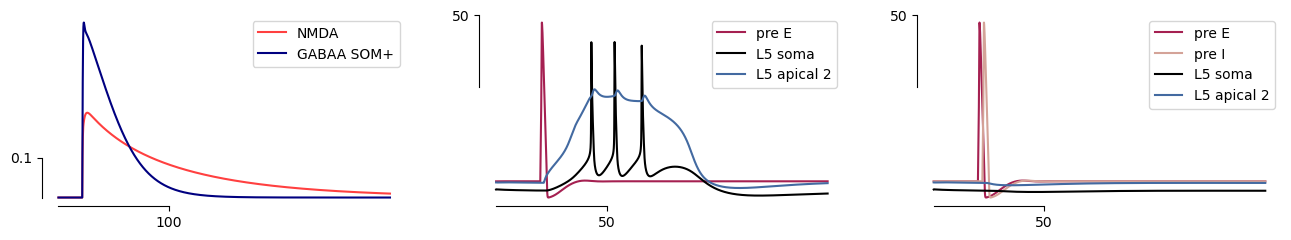

In [ ]:
fig, ax = plt.subplots(1,3, figsize=(16,2.5))

# Clean up NEURON objects from previous cells
# l5pyr sections were created with cell=self, so NEURON holds a C++ ref to the Cell —
# del l5pyr does NOT free it via Python GC alone. Correct order:
#   1. del point processes / NetCons first (unregisters them from NEURON's lists)
#   2. h.delete_section each section explicitly, then clear _nrn_sections
#      (prevents double-free when NEURON eventually finalizes the Cell)
#   3. del remaining Python wrappers
import gc
for _name in ['stim', 'vclamp', 'nc']:
    if _name in globals():
        del globals()[_name]
if 'l5pyr' in globals():
    for _sec in list(l5pyr._nrn_sections.values()):
        h.delete_section(sec=_sec)
    l5pyr._nrn_sections.clear()
    del globals()['l5pyr']
for _name in ['soma', 'soma_pre', 'basal_post']:
    if _name in globals():
        del globals()[_name]
gc.collect()

# pre-synapse excitatory
Epre = h.Section(name='soma')
Epre.L = Epre.diam = 12
Epre.Ra = 100

Epre.cm = 1
Epre.insert('hh') 

# clamp
stim = h.IClamp(Epre(0.5))
stim.delay = 20
stim.dur = 2    
stim.amp = 0.5

# post-synapse
basal_post = h.Section(name='basal1')
basal_post.L = 255
basal_post.diam = 8.5
basal_post.Ra = 100
basal_post.cm = 1
basal_post.insert('pas')

synE = h.NMDA_gao(basal_post(0.5))

ncE = h.NetCon(Epre(0.5)._ref_v, synE, sec=Epre)
ncE.weight[0] = 0.1
ncE.delay = 1

t = h.Vector().record(h._ref_t)
NMDAcurr = h.Vector().record(synE._ref_i)
# vE = h.Vector().record(Epre(0.5)._ref_v)

h.finitialize(-65)
h.continuerun(300)

ax[0].plot(t.as_numpy(), -1*NMDAcurr.as_numpy(), color='r', alpha=0.75, label='NMDA')

# Delete point processes and NetCon BEFORE sections — finitialize walks all
# registered point processes; if they reference a deleted section → segfault
del stim, ncE, synE
del Epre, basal_post
gc.collect()

# pre-synapse inhibitory
Ipre = h.Section(name='soma')
Ipre.L = Ipre.diam = 12
Ipre.Ra = 100
Ipre.cm = 1
Ipre.insert('hh') 

# clamp
stim2 = h.IClamp(Ipre(0.5))
stim2.delay = 20
stim2.dur = 2    
stim2.amp = 0.5

# post-synapse
basal_post = h.Section(name='basal2')
basal_post.L = 255
basal_post.diam = 8.5
basal_post.Ra = 100
basal_post.cm = 1
basal_post.insert('pas')

synI = h.Exp2Syn(basal_post(0.5))
synI.tau1=1.5
synI.tau2=20
synI.e = -80

ncI = h.NetCon(Ipre(0.5)._ref_v, synI, sec=Ipre)
ncI.weight[0] = 0.1
ncI.delay = 1

#vI = h.Vector().record(Ipre(0.5)._ref_v)
t = h.Vector().record(h._ref_t)
gabaacurr = h.Vector().record(synI._ref_i)
h.finitialize(-65)
h.continuerun(300)

ax[0].plot(t.as_numpy(), gabaacurr.as_numpy(), color='navy', label='GABAA SOM+')
ax[0].legend()
del stim2, synI, ncI, t, gabaacurr, basal_post, Ipre

# Connect to L5pyr to check interplay between NMDA and SOM+ at apical_2

# pre-synapse excitatory
Epre = h.Section(name='soma')
Epre.L = Epre.diam = 12
Epre.Ra = 100

Epre.cm = 1
Epre.insert('hh') 

# clamp
stim = h.IClamp(Epre(0.5))
stim.delay = 20
stim.dur = 2    
stim.amp = 0.5



# 
l5pyr = get_l5pyr(add_syn='NMDA_gao', syn_loc='apical_2')
nc = h.NetCon(Epre(0.5)._ref_v, l5pyr.syn, sec=Epre)
nc.weight[0] = 0.1
nc.delay = 1

t = h.Vector().record(h._ref_t)
v_pre_E = h.Vector().record(Epre(0.5)._ref_v)
v_post_apcl = h.Vector().record(l5pyr._nrn_sections['apical_2'](0.5)._ref_v)
v_post_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

h.finitialize()
h.continuerun(150)

ax[1].plot(t, v_pre_E, color='#a52051', label='pre E')
ax[1].plot(t, v_post_soma, color='k', label='L5 soma')
ax[1].plot(t, v_post_apcl, color='#436aa1', label='L5 apical 2')
ax[1].legend()
del stim, nc
del Epre, l5pyr

Epre = h.Section(name='soma')
Epre.L = Epre.diam = 12
Epre.Ra = 100

Epre.cm = 1
Epre.insert('hh') 

# clamp
stim = h.IClamp(Epre(0.5))
stim.delay = 20
stim.dur = 2    
stim.amp = 0.5

# pre-synapse inhibitory
Ipre = h.Section(name='soma')
Ipre.L = Ipre.diam = 12
Ipre.Ra = 100
Ipre.cm = 1
Ipre.insert('hh') 

# clamp
stim2 = h.IClamp(Ipre(0.5))
stim2.delay = 22
stim2.dur = 2    
stim2.amp = 0.5

# 
l5pyr = get_l5pyr(add_syn=['NMDA_gao', 'Exp2Syn', 'gabaa_som+'], syn_loc='apical_2')
nc1 = h.NetCon(Epre(0.5)._ref_v, l5pyr.syn[0], sec=Epre)
nc1.weight[0] = 0.0005
nc1.delay = 1

nc2 = h.NetCon(Ipre(0.5)._ref_v, l5pyr.syn[1], sec=Ipre)
nc2.weight[0] = 0.0005
nc2.delay = 1

nc3 = h.NetCon(Ipre(0.5)._ref_v, l5pyr.syn[2], sec=Ipre)
nc3.weight[0] = 0.0075
nc3.delay = 1

t = h.Vector().record(h._ref_t)
v_pre_E = h.Vector().record(Epre(0.5)._ref_v)
v_pre_I = h.Vector().record(Ipre(0.5)._ref_v)

v_post_apcl = h.Vector().record(l5pyr._nrn_sections['apical_2'](0.5)._ref_v)
v_post_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

h.finitialize()
h.continuerun(150)

ax[2].plot(t, v_pre_E, color='#a52051', label='pre E')
ax[2].plot(t, v_pre_I, color='#d4a398', label='pre I')

ax[2].plot(t, v_post_soma, color='k', label='L5 soma')
ax[2].plot(t, v_post_apcl, color='#436aa1', label='L5 apical 2')
ax[2].legend()

for i in [1,2]:
    ax[i].spines['left'].set_bounds([0, 50])
    ax[i].set_yticks([50])
    ax[i].spines['bottom'].set_bounds([0, 50])
    ax[i].set_xticks([50])
    ax[i].spines['top'].set_visible(False)
    ax[i].spines['right'].set_visible(False)A

ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)

ax[0].spines['left'].set_bounds([0, 0.1])
ax[0].set_yticks([0.1])
ax[0].spines['bottom'].set_bounds([0, 100])
ax[0].set_xticks([100])

fig.savefig(f'{pathfig}/NMDA_vs_GABAA.png')
fig.savefig(f'{pathfig}/NMDA_vs_GABAA.pdf')